## Part 1: Analyzing Best-Seller Trends Across Product Categories

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
pd.set_option('display.max_columns', None)

In [6]:
df = pd.read_csv("dataset/amz_uk_price_prediction_dataset.csv")

In [3]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
df.shape

(2443651, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 495.8 MB


**Crosstab Analysis**:

In [10]:
crosstab1 = pd.crosstab(df['category'], df['isBestSeller'])
display(crosstab1)

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [31]:
top_categories = (crosstab1[True].sort_values(ascending=False).head(50))
display(top_categories)

category
Grocery                                       556
Health & Personal Care                        552
Baby                                          341
Sports & Outdoors                             330
Power & Hand Tools                            306
Beauty                                        302
Pet Supplies                                  285
Arts & Crafts                                 230
Women                                         213
Men                                           169
PC & Video Games                              157
Storage & Organisation                        155
Hardware                                      146
Large Appliances                              144
Building Supplies                             134
Office Supplies                               133
Customers' Most Loved                         111
Agricultural Equipment & Supplies             109
Gardening                                     106
Luggage and travel gear                  

Business question: Are there categories where being a best-seller is more prevalent?

the top 10 categories with the most prevalecent best-seller tag are in order:Grocery with 556 items,  Health & Personal Care with 552 items, Baby with 341 items, Sports & Outdoors with 330 items, Power & Hand Tools with 306, Beauty with 302 items, Pet Supplies with 285 itmes, Arts & Crafts with 230 items,Women with 213 and Men with 169 items.

**Statistical Tests**

In [ ]:
from scipy.stats import chi2_contingency

_, chi2_pvalue, _, _  = chi2_contingency(crosstab1)

display(float(chi2_pvalue) < 0.05)


True

np.float64(0.0)

Since the p result for the Chi square test is less than 5%, it means that there is statistical  significant association between product category and Best Seller status. This suggests that the proportion of best-selling products differs across product categories.

In [15]:
from scipy.stats.contingency import association

association(crosstab1, method="cramer")

0.1222829439760564

When applying the Cramer method to the 2 variables, Product Category and Best Seller status, it shows a weak association between both. This result combined with Chi squared result indicates that Product category and best-seller status are not independent and that the overall association is small.

**Visualization**

In [ ]:
crosstab_percent = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
) * 100

display(crosstab_percent.round(2))

top_categories_percent = (
    crosstab_percent[True]
    .sort_values(ascending=False)
    .head(20)
)

display(top_categories)

isBestSeller,False,True
category,,
3D Printers,99.60,0.40
3D Printing & Scanning,99.95,0.05
Abrasive & Finishing Products,98.00,2.00
Action Cameras,99.94,0.06
Adapters,98.82,1.18
...,...,...
Wind Instruments,97.20,2.80
Window Treatments,97.91,2.09
Women,98.80,1.20


category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
Billiard, Snooker & Pool          3.212851
Pet Supplies                      3.020028
Home Brewing & Wine Making        2.845528
Mirrors                           2.800000
Wind Instruments                  2.800000
Name: True, dtype: float64

<Axes: title={'center': 'Top 20 Categories by Best-Seller Percentage'}, xlabel='Product Category', ylabel='Best-Sellers (%)'>

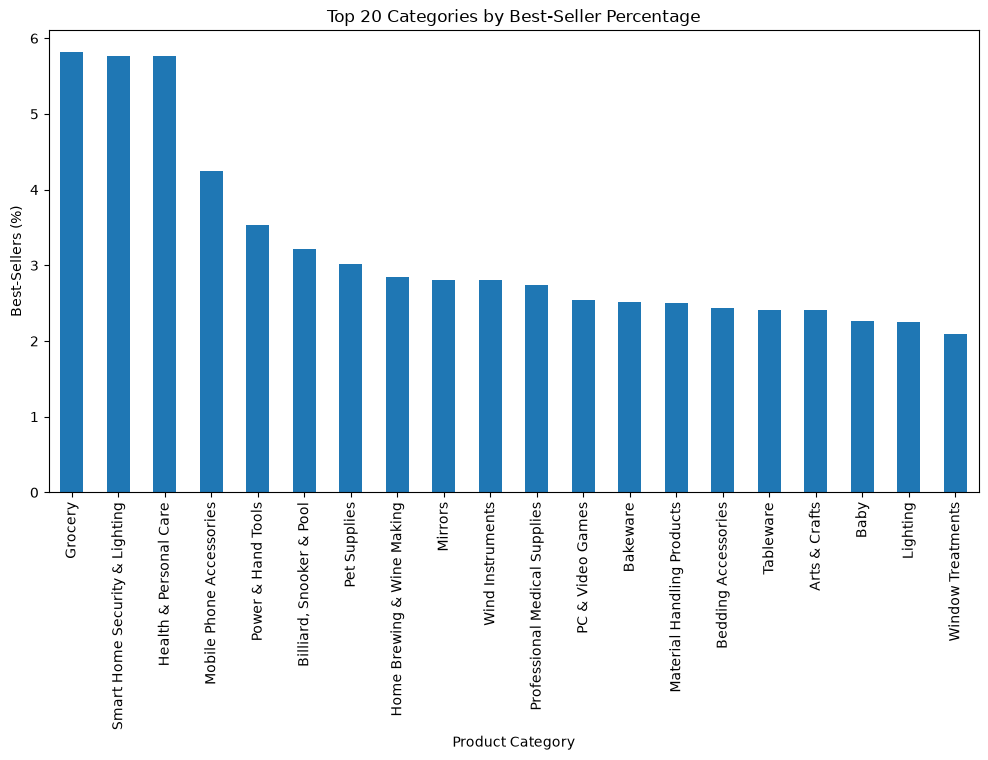

In [42]:
top_categories_percent.plot.bar(
    figsize=(12, 6),
    title="Top 20 Categories by Best-Seller Percentage",
    xlabel="Product Category",
    ylabel="Best-Sellers (%)"
)

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.


In [43]:
#removing outliers

def outlier_slayer(data, method):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [47]:
outliers = outlier_slayer(df["price"], method="remove")
df_clean = df.drop(index=outliers.index)

In [48]:
# Checking results
print("Outliers removed:", len(outliers))
print("Remaining rows:", len(df_clean))

Outliers removed: 327688
Remaining rows: 2115963


Violin Plot

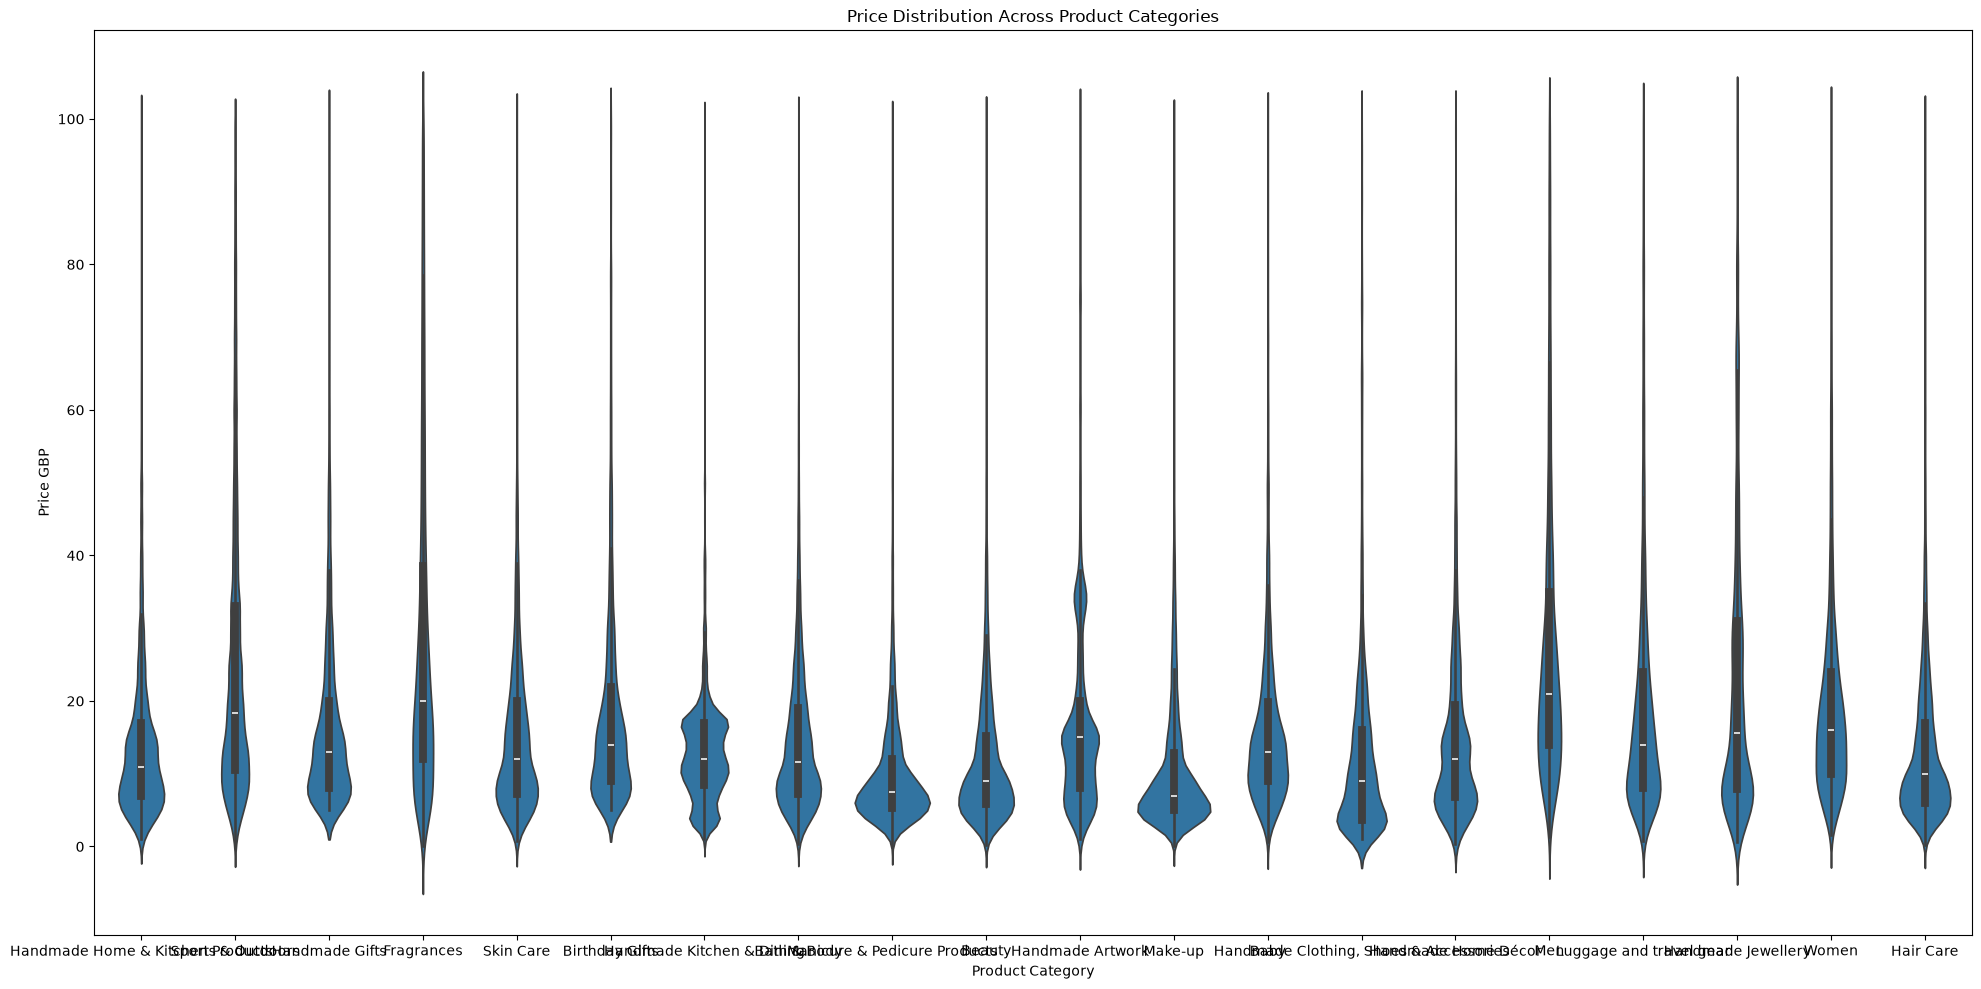

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt

top_20 = df_clean["category"].value_counts().head(20).index
df_plot = df_clean[df_clean["category"].isin(top_20)]

plt.figure(figsize=(20, 10))

sns.violinplot(
    data=df_plot,
    x="category",
    y="price"
)

plt.title("Price Distribution Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price GBP")
plt.tight_layout()
plt.show()

In [58]:
df_plot.groupby("category")["price"].median().sort_values(ascending=False)

category
Men                                       20.990
Fragrances                                20.000
Sports & Outdoors                         18.320
Women                                     15.990
Handmade Jewellery                        15.600
Handmade Artwork                          14.990
Luggage and travel gear                   13.990
Birthday Gifts                            13.990
Baby                                      12.990
Handmade Gifts                            12.990
Handmade Kitchen & Dining                 12.000
Skin Care                                 12.000
Handmade Home Décor                       11.990
Bath & Body                               11.635
Handmade Home & Kitchen Products          10.990
Hair Care                                  9.970
Beauty                                     8.990
Handmade Clothing, Shoes & Accessories     8.990
Manicure & Pedicure Products               7.500
Make-up                                    7.000
Name: price

Men is the category with the highest median price at 20.99 GBP, followed closely by Fragances at 20 GPB

***Bar Chart***

<Axes: title={'center': 'Average Price of the Top 10 Product Categories'}, xlabel='Product Category', ylabel='Avg Price GBP'>

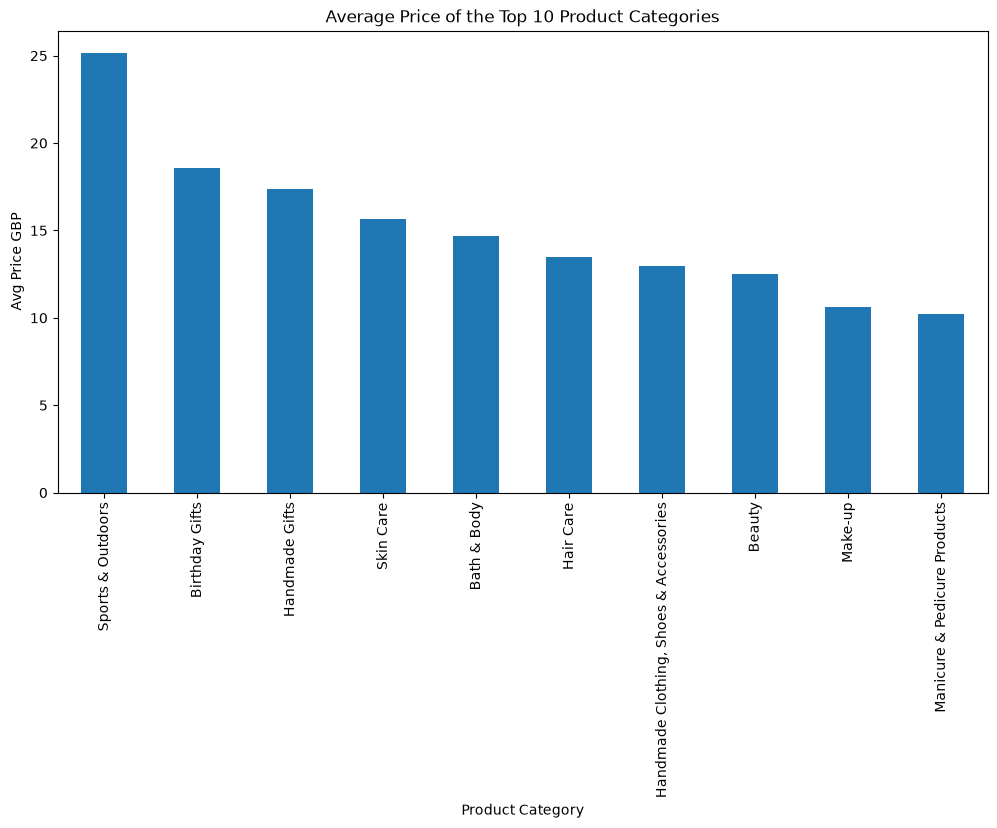

In [62]:
top_10 = df_clean["category"].value_counts().head(10).index

avg_price = df_clean[df_clean["category"].isin(top_10)].groupby("category")["price"].mean().sort_values(ascending=False)

avg_price.plot.bar(
    figsize=(12, 6),
    title="Average Price of the Top 10 Product Categories",
    xlabel="Product Category",
    ylabel="Avg Price GBP",
    )


The category Sports and Outdoors has the highest average price on its products.

**Box Plots**:

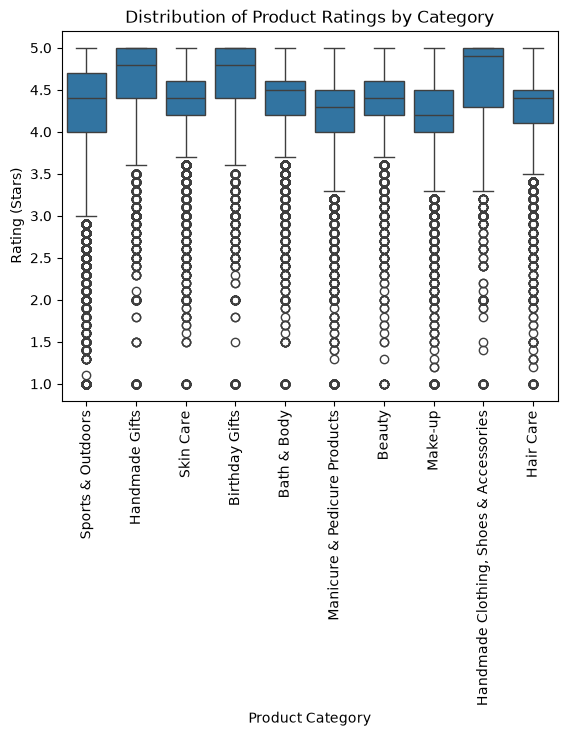

In [64]:
top_10_rating = df["category"].value_counts().head(10).index

#excluding the zero star ratings
df_plot_2 = df[
    df["category"].isin(top_10) &
    (df["stars"] > 0)
]

sns.boxplot(
    data=df_plot_2,
    x="category",
    y="stars")

plt.title("Distribution of Product Ratings by Category")
plt.xlabel("Product Category")
plt.ylabel("Rating (Stars)")
plt.xticks(rotation=90)
plt.show()

In [66]:
df_plot_2.groupby("category")["stars"].median().sort_values(ascending=False)

category
Handmade Clothing, Shoes & Accessories    4.9
Birthday Gifts                            4.8
Handmade Gifts                            4.8
Bath & Body                               4.5
Beauty                                    4.4
Hair Care                                 4.4
Sports & Outdoors                         4.4
Skin Care                                 4.4
Manicure & Pedicure Products              4.3
Make-up                                   4.2
Name: stars, dtype: float64

The Category "Handmade CLothnig, Shoes and Accesories" recieves the highest median rating at 4.9 

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Correlation Coefficients**

In [67]:
#correlation coefficient between `price` and `stars`
round(float(df_clean["price"].corr(df_clean["stars"], method="pearson")), 2)

-0.08

In [68]:
df_clean["price"].corr(df_clean["stars"], method="spearman")

np.float64(-0.06679697280768314)

The Pearson correlation coefficient of −0.08 indicates a negligible linear relationship between product price and customer ratings. Overall it seems that product price is not a useful linear predictor of customer ratings.

2. **Visualizations**:

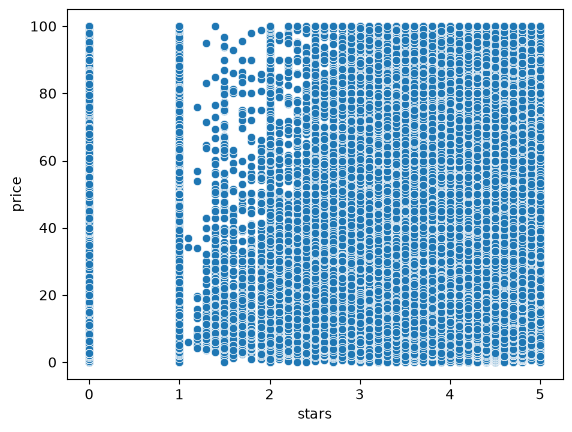

In [70]:
#scatter plot
sns.scatterplot(data=df_clean, x='stars', y='price')
plt.show()

Some patterns are visible:

1) Products with ratings between 2 and 5 stars are found across almost the entire displayed price range (£0–£100). Higher prices do not appear to correspond consistently to higher ratings.

2) Ratings appear in discrete increments, creating vertical bands rather than a continuous distribution.

3) There are substantial vertical clusters at 0 and 1 stars. The zero ratings may represent unrated products and should be investigated before interpreting the relationship.

4) The space between the 0 and 1 rating suggest that the minimum star rating that a customer can give to a product is 1

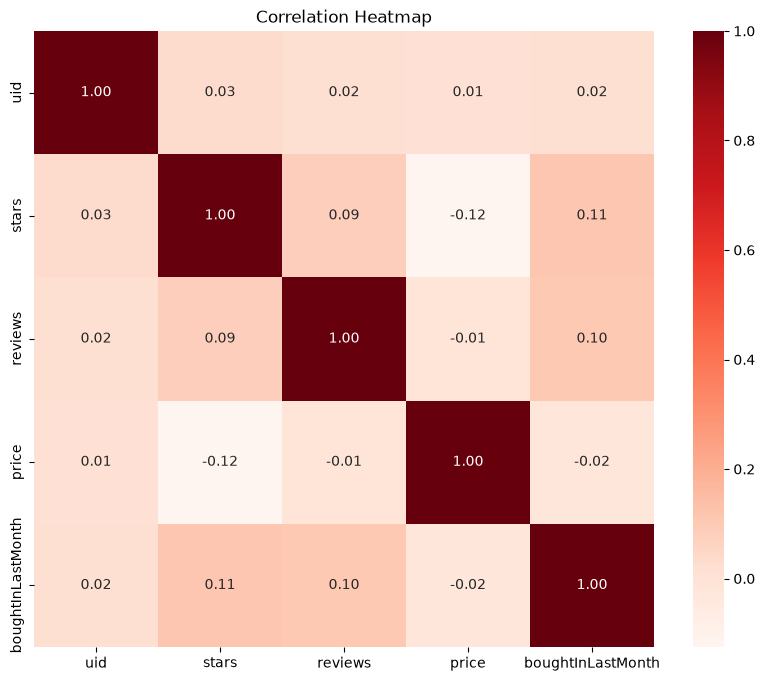

In [7]:
#correlation heatmap to visualize correlations between all numerical variables
import seaborn as sns
import matplotlib.pyplot as plt

# Selecting numerical columns
num = df.select_dtypes(include="number")

# Calculate correlation matrix
corr = num.corr()

# Create heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="Reds", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

There is no strong correlation between numerical variables in the dataset.

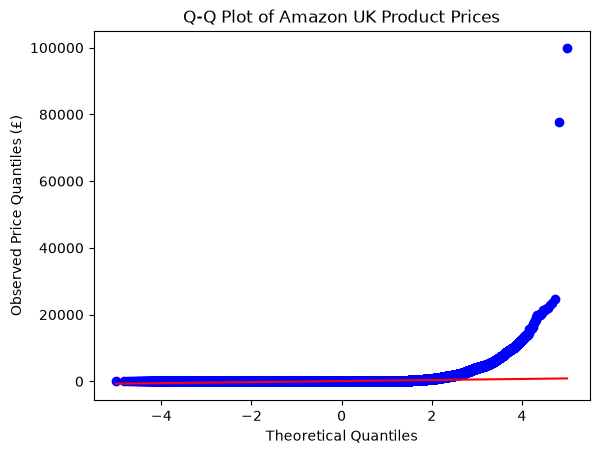

In [9]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(df["price"].dropna(), dist="norm", plot=plt)

plt.title("Q-Q Plot of Amazon UK Product Prices")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Observed Price Quantiles (£)")
plt.show()

the amazon product prices do not follow a normal distribution